(quickstart)=
# Quickstart (Python)

This page annotates the clusters of a small public dataset, 2,700 peripheral blood mononuclear
cells (PBMCs) from 10x Genomics, starting from a fresh Python session. The preprocessing runs
locally in a few minutes; the annotation itself runs on CyteType's servers. The outputs on this
page come from a real run of this notebook.

Before you start, you need:

- Python 3.12 or newer with CyteType and Scanpy installed, for example with
  `pip install cytetype "scanpy[leiden]"` (see [Installation](installation.md)).
- A CyteType sign-in on this machine. Run `cytetype setup` once in a terminal
  (see [Sign in and API keys](sign-in.md)).

Working in R? The same workflow with Seurat is in the [R quickstart](quickstart-r.md).

## Load and cluster the data

CyteType annotates the clusters you define, using the marker genes you compute for them. These
are the standard Scanpy steps: quality control, normalization, clustering and marker detection.

In [1]:
# Import Scanpy for preprocessing and CyteType for annotation.
import scanpy as sc

from cytetype import CyteType, marker_dotplot

# Use a consistent figure resolution for the plots below.
sc.set_figure_params(dpi=100, frameon=False)

Started: 2026-10-18T09:26:00.316829Z | Wall time: 1.164 s

In [2]:
# Download the 10x Genomics PBMC 3k dataset with raw counts.
adata = sc.datasets.pbmc3k()
adata

  0%|          | 0.00/5.58M [00:00<?, ?B/s]

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'

Started: 2026-10-18T09:26:01.481775Z | Wall time: 1.306 s

In [3]:
# Remove cells with few detected genes and genes detected in very few cells.
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)

# Drop cells with a high fraction of mitochondrial reads.
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
adata = adata[adata.obs["pct_counts_mt"] < 5].copy()

# Keep the raw counts in a layer; CyteType uploads them with the normalized data.
adata.layers["counts"] = adata.X.copy()

# Normalize and log-transform; CyteType expects log-normalized values in adata.X.
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

Started: 2026-10-18T09:26:02.789262Z | Wall time: 1.919 s

In [4]:
# Find highly variable genes, reduce dimensions and build the neighbor graph.
sc.pp.highly_variable_genes(adata, n_top_genes=2000)
sc.tl.pca(adata, mask_var="highly_variable")
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=40)

# Cluster with Leiden and compute a UMAP for plotting and for the report.
sc.tl.leiden(adata, resolution=0.8, flavor="igraph", n_iterations=2, key_added="leiden")
sc.tl.umap(adata)

Started: 2026-10-18T09:26:04.709565Z | Wall time: 12.039 s

In [5]:
# Rank marker genes for each cluster; CyteType reads them from adata.uns.
sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon", key_added="rank_genes_leiden")

Started: 2026-10-18T09:26:16.749572Z | Wall time: 0.631 s

## Prepare the annotation

`CyteType` checks the inputs and summarizes each cluster: its top marker genes, how widely genes
are expressed, and the cell metadata. It also writes two files to the working directory,
`vars.h5` (expression) and `obs.duckdb` (cell metadata and UMAP coordinates), which are uploaded
with the job. [Prepare your data](../guides/prepare-data.md) explains each requirement.

In [6]:
# Check the inputs and build the files that are uploaded with the job.
annotator = CyteType(adata, group_key="leiden", rank_key="rank_genes_leiden")

Auto-detected gene symbols in adata.var_names (index) (0% ID-like, 100% unique).


Using coordinates from 'X_umap' for visualization.


Materialized canonical gene symbols in temporary column '__cytetype_gene_symbols' from adata.var_names.


Calculating expression percentages:   0%|          | 0/1 [00:00<?, ?chunk/s]

Extracting marker genes...


...

Writing normalized counts:   0%|          | 0/1 [00:00<?, ?batch/s]

Writing raw counts to H5 artifact:   0%|          | 0/2 [00:00<?, ?batch/s]

Writing obs data to duckdb artifact...


Data preparation completed. Ready for submitting jobs.


Started: 2026-10-18T09:26:17.383132Z | Wall time: 0.438 s

## Run the annotation

`run()` uploads the files, submits the job and waits for the results. The report link is printed
as soon as the job starts, so you can follow its progress in the browser. If your session ends
before the job finishes, the job keeps running and you can fetch the results later (see
[Run, monitor and rerun jobs](../guides/running-jobs.md)).

The study context tells CyteType what the sample is. Include the organism, tissue and condition;
[Study context and metadata](../guides/study-context.md) has more examples.

In [7]:
# Describe the study, submit the job and wait for it to finish.
adata = annotator.run(
    study_context=(
        "Peripheral blood mononuclear cells (PBMCs) from a healthy human donor, "
        "profiled with 10x Genomics 3' single-cell RNA-seq."
    ),
    metadata={"title": "PBMC 3k quickstart"},
)

Uploading vars.h5 artifact...


Uploading:   0%|          | 0/1 [00:00<?, ?chunk/s]


Uploading obs.duckdb artifact...


Uploading:   0%|          | 0/1 [00:00<?, ?chunk/s]

CyteType job submitted.


...


[TRACK PROGRESS]
https://cytetype.nygen.io/report/a1a55802-b137-4617-aab0-9a6fe65af05e


✓ Job a1a55802-b137-4617-aab0-9a6fe65af05e completed successfully.


     Annotation labels → adata.obs['cytetype_annotation_leiden']
   Cell Ontology terms → adata.obs['cytetype_cellOntologyTerm_leiden']
Cell Ontology term IDs → adata.obs['cytetype_cellOntologyTermID_leiden']
           Cell states → adata.obs['cytetype_cellState_leiden']
   Reviewer confidence → adata.obs['cytetype_reviewerConfidence_leiden']
          Full results → adata.uns['cytetype_results']


Report:
https://cytetype.nygen.io/report/a1a55802-b137-4617-aab0-9a6fe65af05e


Started: 2026-10-18T09:26:17.822558Z | Wall time: 472.362 s

## Explore the results

Every cell now carries its cluster's annotation in `adata.obs`: the cell type label, its Cell
Ontology term and ID, the cell state and the reviewer's confidence.

In [8]:
# Show one row per cluster with its label, Cell Ontology term ID and reviewer confidence.
columns = [
    "leiden",
    "cytetype_annotation_leiden",
    "cytetype_cellOntologyTermID_leiden",
    "cytetype_reviewerConfidence_leiden",
]
adata.obs[columns].drop_duplicates().sort_values("leiden").reset_index(drop=True)

,leiden,cytetype_annotation_leiden,cytetype_cellOntologyTermID_leiden,cytetype_reviewerConfidence_leiden
0,0,CD8+ effector memory T cell,CL:0000909,High
1,1,Naive B cell,CL:0000788,High
2,2,CD4+ conventional T cell,CL:0000624,Moderate
3,3,Classical monocyte,CL:0000860,High
4,4,CD56-dim NK cell,CL:0000939,High
5,5,Non-classical monocyte,CL:0000875,Moderate
6,6,Naive CD4+ T cell,CL:0000895,Moderate
7,7,Dendritic cell,CL:0000451,Moderate
8,8,Platelet,CL:0000233,High


Started: 2026-10-18T09:34:10.189276Z | Wall time: 0.039 s

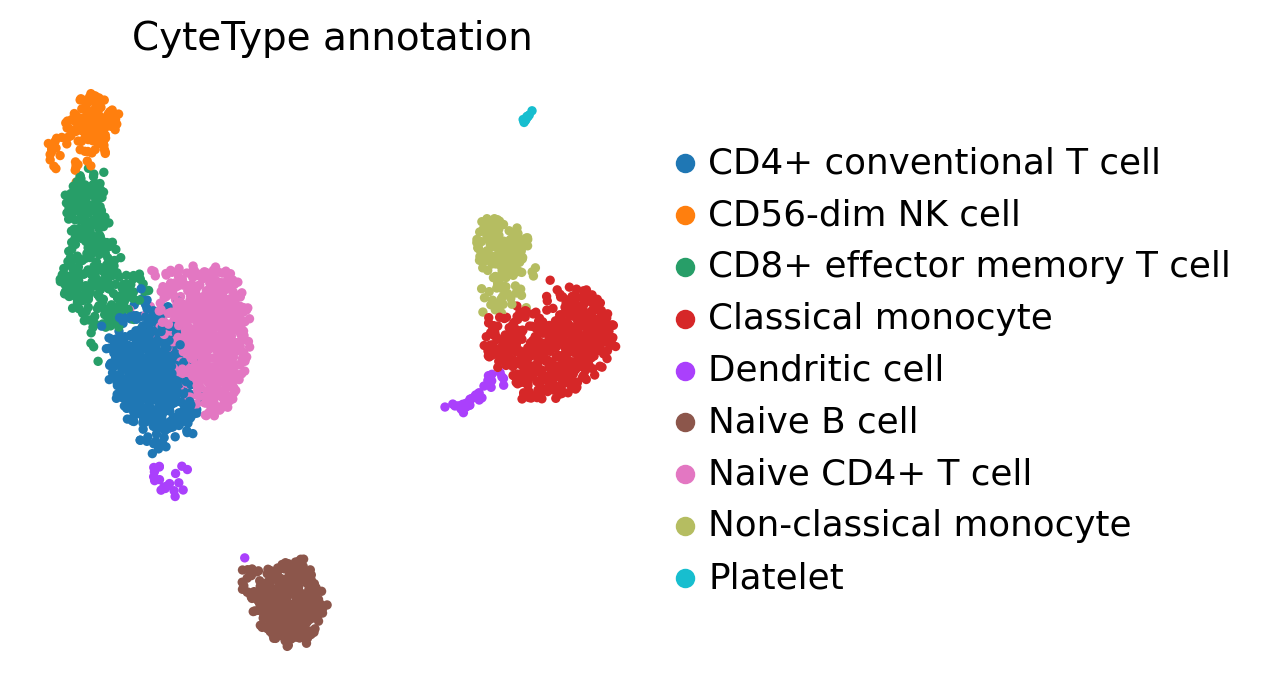

Started: 2026-10-18T09:34:10.233725Z | Wall time: 0.548 s

In [9]:
# Plot the CyteType labels on the UMAP.
sc.pl.umap(adata, color="cytetype_annotation_leiden", title="CyteType annotation")

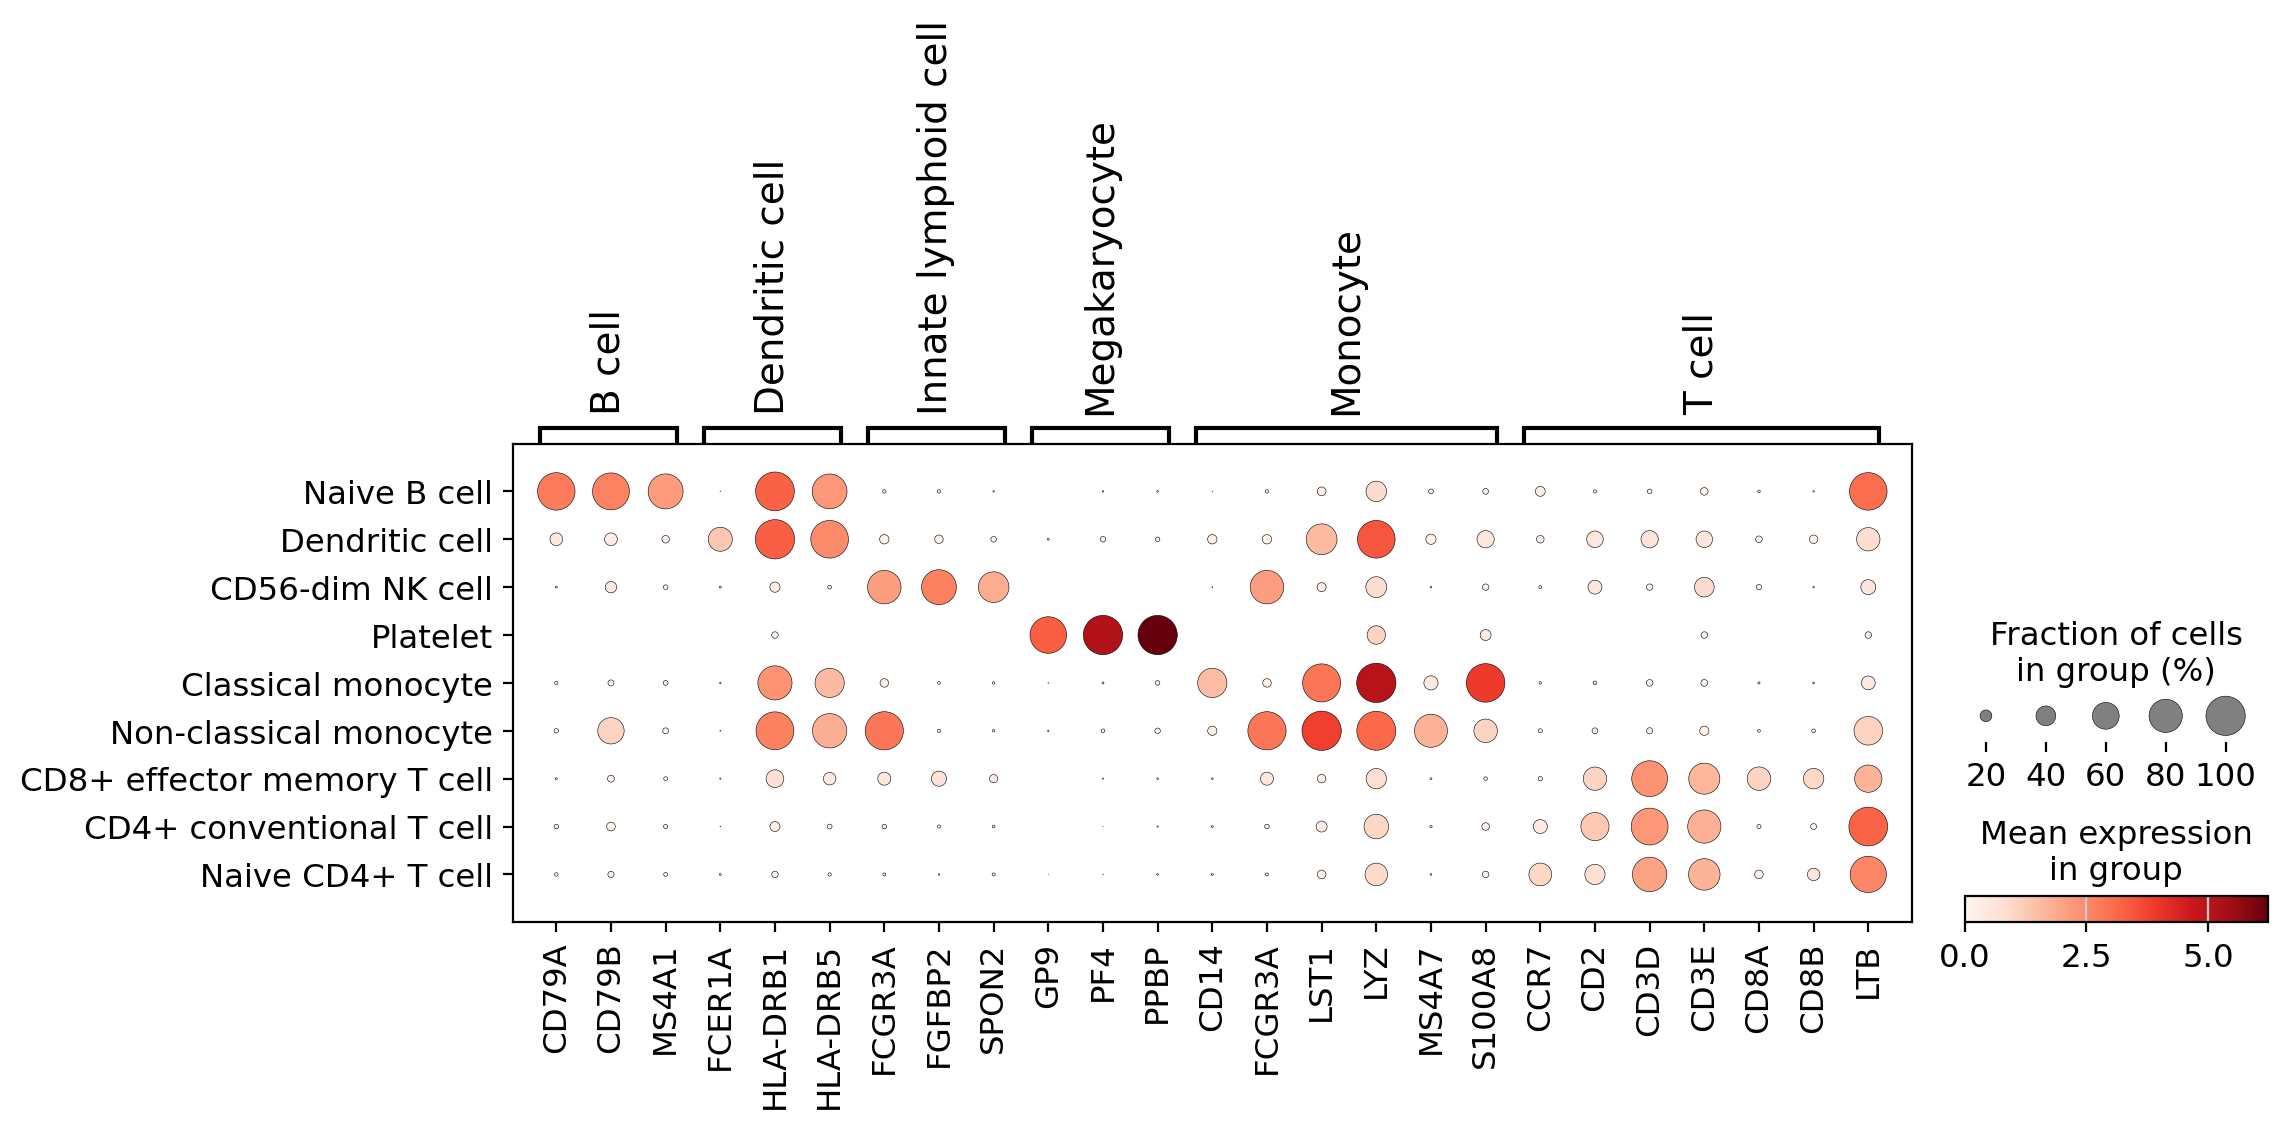

Started: 2026-10-18T09:34:10.786011Z | Wall time: 0.762 s

In [10]:
# Show the marker genes that support each label, grouped by cell type.
marker_dotplot(adata, group_key="leiden")

## Read the evidence

`get_results()` returns the full results, including the evidence behind each label. Each entry
in `annotations` describes one cluster.

In [11]:
# Look at the evidence recorded for the first cluster.
results = annotator.get_results()
first = results["annotations"][0]
{key: first[key] for key in ("clusterId", "annotation", "cellState", "reviewerConfidence", "supportingMarkers")}

Retrieving results with prefix: 'cytetype'


{'clusterId': '0',
 'annotation': 'CD8+ effector memory T cell',
 'cellState': 'Cytotoxic Effector Program',
 'reviewerConfidence': 'High',
 'supportingMarkers': ['CD8A',
  'CD8B',
  'CD3D',
  'KLRG1',
  'HOPX',
  'SAMD3',
  'FGFBP2',
  'GZMK',
  'CCL5',
  'CST7',
  'PRF1',
  'NKG7']}

Started: 2026-10-18T09:34:11.552476Z | Wall time: 0.023 s

The interactive report holds the full reasoning for every cluster: the candidate cell types that
were considered, the marker evidence, quality-control checks and pathway context. The report for
this example is public; your own reports are private unless you share them (see
[Visibility and sharing](../platform/sharing.md)).

In [12]:
# Get the link to the interactive report.
adata.uns["cytetype_jobDetails"]["report_url"]

'https://cytetype.nygen.io/report/a1a55802-b137-4617-aab0-9a6fe65af05e'

Started: 2026-10-18T09:34:11.580426Z | Wall time: 0.011 s

## Save and clean up

The results are stored in `adata.obs` and `adata.uns`, so they are saved with the AnnData file.
`cleanup()` deletes the upload files and the helper column that CyteType added to `adata.var`.

In [13]:
# Remove the upload files and the temporary helper column.
annotator.cleanup()

# Save the annotated data; the CyteType results are saved with it.
adata.write_h5ad("pbmc3k_cytetype.h5ad")

Deleted artifact file: vars.h5


Deleted artifact file: obs.duckdb


Deleted temporary canonical gene-symbol column '__cytetype_gene_symbols'.


Started: 2026-10-18T09:34:11.596663Z | Wall time: 0.349 s

## Next steps

- [Prepare your data](../guides/prepare-data.md): requirements for clusters, marker genes and
  gene symbols.
- [The CyteType report](../results/report.md): every section of the report.
- [Results in AnnData and Seurat](../results/results-in-your-data.md): all columns and keys.
- [Interpret and review results](../results/interpreting-results.md): confidence,
  heterogeneity and limits.
- [Use your own LLM](../guides/llm-configuration.md): run CyteType with your own model provider.